# Κυρτό περίβλημα

Το κυρτό περίβλημα ενός συνόλου σημείων στο επίπεδο είναι το μικρότερο κυρτό σχήμα που τα περιέχει όλα. Ένα σχήμα ονομάζεται κυρτό όταν, για οποιαδήποτε δύο σημεία του, το ευθύγραμμο τμήμα που τα ενώνει βρίσκεται ολόκληρο μέσα σε αυτό. Διαισθητικά, το περίβλημα μοιάζει με ένα λάστιχο που τεντώνεται γύρω από καρφιά τοποθετημένα στο επίπεδο και ακουμπά μόνο στα εξωτερικά από αυτά.

## 1. Υλοποίηση Αλγορίθμων για την Εύρεση Κυρτού Περιβλήματος στο Επίπεδο

### Βοηθητικές βιβλιοθήκες για την υλοποίηση και παρουσίαση των αλγορίθμων

In [ ]:
# standard library 
import random
import time
from functools import cmp_to_key
from typing import List, Tuple

# third-party libraries
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import numpy as np
import pandas as pd
from scipy.spatial import ConvexHull, Delaunay

### Υπολογισμός προσανατολισμού τριών σημείων

In [2]:
def orientation(o, a, b):
    val = (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])
    if abs(val) < 1e-9:
        return 0 # collinear
    return 1 if val > 0 else -1   # 1 = left turn, -1 = right turn

## Αυξητικός Αλγόριθμος (Graham Scan)

In [ ]:
def graham_scan(points):
    # sort points by x
    points = sorted(points)
    
    lower_hull = []
    upper_hull = []

    # find lower hull, go through points left to right
    for p in points:
        while len(lower_hull) >= 2 and (orientation(lower_hull[-2], lower_hull[-1], p) <= 0):
            lower_hull.pop()
        lower_hull.append(p)

    # find upper hull, go through points right to left
    for p in reversed(points):
        while len(upper_hull) >= 2 and (orientation(upper_hull[-2], upper_hull[-1], p) <= 0):
            upper_hull.pop()
        upper_hull.append(p)

     # concatenate lower and upper hulls, removing the last point of each
    return lower_hull[:-1] + upper_hull[:-1]

Ο αυξητικός αλγόριθμος ξεκινά ταξινομώντας τα σημεία κατά x (και, σε ισοβαθμία, κατά y). Στη συνέχεια κατασκευάζονται χωριστά το κάτω και το άνω τμήμα του περιβλήματος (lower_hull και upper_hull): το κάτω διατρέχοντας τα σημεία από αριστερά προς τα δεξιά και το άνω από δεξιά προς τα αριστερά. Κάθε νέο σημείο προστίθεται στο τέλος της λίστας, αφού πρώτα αφαιρεθούν τα προηγούμενα σημεία που θα σχημάτιζαν δεξιά στροφή (ή θα ήταν συνευθειακά), γιατί δεν μπορούν να ανήκουν στο περίβλημα. Τέλος, οι δύο λίστες ενώνονται, αφού αφαιρεθεί το τελευταίο σημείο της καθεμίας, ώστε τα κοινά άκρα να μην εμφανίζονται δύο φορές.

Η συνολική πολυπλοκότητα είναι O(n log n). Η ταξινόμηση κοστίζει O(n log n), ενώ η κατασκευή των δύο τμημάτων γίνεται σε γραμμικό χρόνο, αφού κάθε σημείο προστίθεται και αφαιρείται το πολύ μία φορά.

## Αλγόριθμος του περιτυλίγματος (Jarvis March)

In [4]:
def gift_wrapping(points):
    # base case, only 2 points
    if len(points) < 3:
        return points

    hull = []
    
    # find the leftmost point
    l = 0
    for i in range(1, len(points)):
        if points[i][0] < points[l][0]:
            l = i

    # current point on the convex hull
    p = l
    while True:
        # add current point to the convex hull
        hull.append(points[p])
        # calculate for the next hull point
        q = (p + 1) % len(points)
        for i in range(len(points)):
            # check if current point is more ccw than q relative to p
            if orientation(points[p], points[i], points[q]) == -1:
                q = i
        # move to next point
        p = q
        # were back to the first point, we are done
        if p == l:
            break

    return hull

Ο αλγόριθμος του περιτυλίγματος (Jarvis March) ξεκινά από το αριστερότερο σημείο, που ανήκει σίγουρα στο περίβλημα. Σε κάθε βήμα εξετάζονται όλα τα σημεία και επιλέγεται εκείνο που βρίσκεται πιο αριστερά ως προς την κατεύθυνση από το τρέχον σημείο, δηλαδή το πιο «αριστερόστροφο». Με αυτόν τον τρόπο το περίβλημα «τυλίγεται» γύρω από το σύνολο, αντίθετα προς τη φορά των δεικτών του ρολογιού, μέχρι να επιστρέψει ο αλγόριθμος στο αρχικό σημείο.

Κάθε βήμα κοστίζει O(n), αφού ελέγχονται όλα τα σημεία, και τα βήματα είναι τόσα όσα τα σημεία του περιβλήματος. Η πολυπλοκότητα είναι λοιπόν O(n·h), όπου n ο αριθμός των σημείων και h ο αριθμός των κορυφών του περιβλήματος. Ο αλγόριθμος είναι αποδοτικός όταν το h είναι μικρό, ενώ στη χειρότερη περίπτωση (h = n, π.χ. όταν όλα τα σημεία βρίσκονται σε κύκλο) γίνεται O(n²) και υπολείπεται του Graham Scan.

## Αλγόριθμος Διαίρει και Βασίλευε

In [5]:
def compare(p1, p2, mid):
    # we wanna sort points counter-clockwise (from mid)
    dx1, dy1 = p1[0] - mid[0], p1[1] - mid[1]
    dx2, dy2 = p2[0] - mid[0], p2[1] - mid[1]
    
    # figure out which quadrant each point is in relative to mid
    quad1 = 1 if dx1 >= 0 and dy1 >= 0 else 2 if dx1 < 0 and dy1 >= 0 else 3 if dx1 < 0 and dy1 < 0 else 4
    quad2 = 1 if dx2 >= 0 and dy2 >= 0 else 2 if dx2 < 0 and dy2 >= 0 else 3 if dx2 < 0 and dy2 < 0 else 4
    
    # the points are in different quadrants, just order by quadrant number
    if quad1 != quad2:
        return quad1 - quad2
    
    # the points are in the same quadrant, check cross product
    cross = dx1 * dy2 - dy1 * dx2
    if cross == 0:
        return 0
    return -1 if cross > 0 else 1

def brute_hull(points: List[Tuple[int, int]]) -> List[Tuple[int, int]]:
    if len(points) <= 1:
        return points[:]
    
    # find midpoint
    mid_x = sum(p[0] for p in points) / len(points)
    mid_y = sum(p[1] for p in points) / len(points)
    mid = (mid_x, mid_y)
    
    # remove duplicates to avoid weird behavior
    unique_points = list(set(points))
    
    # sort points counter clockwise
    unique_points.sort(key=cmp_to_key(lambda p1, p2: compare(p1, p2, mid)))
    
    # simple graham scan
    stack = []
    for pt in unique_points:
        while len(stack) >= 2 and orientation(stack[-2], stack[-1], pt) <= 0:
            stack.pop()
        stack.append(pt)
    return stack

def divide_and_conquer(points: List[Tuple[int, int]]) -> List[Tuple[int, int]]:
    # sort points and remove duplicates (x then y)
    points = sorted(set(points))
    
    # base case: small sets
    if len(points) <= 5:
        return brute_hull(points)
    
    mid = len(points) // 2
    left = points[:mid]
    right = points[mid:]
    
    # recursive call find hulls for left and right half
    left_hull = divide_and_conquer(left)
    right_hull = divide_and_conquer(right)
    
    # merge the hulls into one big hull
    return merge_hulls(left_hull, right_hull)

def merge_hulls(left_hull: List[Tuple[int, int]], right_hull: List[Tuple[int, int]]) -> List[Tuple[int, int]]:
    
    # left_hull is empty, return right_hull
    if not left_hull:
        return right_hull
    # right_hull is empty, return left_hull
    if not right_hull:
        return left_hull
    # left_hull and right_hull are both singletons, concatenate them
    if len(left_hull) == 1 and len(right_hull) == 1:
        return left_hull + right_hull 

    # find the rightmost point of the left hull and the leftmost point of the right hull
    l_rightmost = max(range(len(left_hull)), key=lambda i: left_hull[i][0])
    r_leftmost = min(range(len(right_hull)), key=lambda i: right_hull[i][0])

    # find lower tangent, moving around points till we cant go lower
    lower_left, lower_right = l_rightmost, r_leftmost
    for _ in range(len(left_hull) + len(right_hull)):  # safeguard for infinite loop
        changed = False
        while orientation(right_hull[lower_right], left_hull[lower_left], left_hull[(lower_left - 1) % len(left_hull)]) >= 0:
            lower_left = (lower_left - 1) % len(left_hull)
            changed = True
        while orientation(left_hull[lower_left], right_hull[lower_right], right_hull[(lower_right + 1) % len(right_hull)]) <= 0:
            lower_right = (lower_right + 1) % len(right_hull)
            changed = True
        if not changed:
            break

    # find upper tangent, moving around points till we cant go higher
    upper_left, upper_right = l_rightmost, r_leftmost
    for _ in range(len(left_hull) + len(right_hull)):  # safeguard for infinite loop
        changed = False
        while orientation(left_hull[upper_left], right_hull[upper_right], right_hull[(upper_right - 1) % len(right_hull)]) >= 0:
            upper_right = (upper_right - 1) % len(right_hull)
            changed = True

        while orientation(right_hull[upper_right], left_hull[upper_left], left_hull[(upper_left + 1) % len(left_hull)]) <= 0:
            upper_left = (upper_left + 1) % len(left_hull)
            changed = True
        if not changed:
            break

    # merge points of upper and lower tangents into one hull
    merged_hull = []
    i = upper_left
    while True:
        merged_hull.append(left_hull[i])
        if i == lower_left:
            break
        i = (i + 1) % len(left_hull)

    i = lower_right
    while True:
        merged_hull.append(right_hull[i])
        if i == upper_right:
            break
        i = (i + 1) % len(right_hull)

    return merged_hull

Ο αλγόριθμος Divide & Conquer υπολογίζει το κυρτό περίβλημα με αναδρομή. Τα σημεία ταξινομούνται κατά x, αφαιρούνται τα διπλότυπα και το σύνολο χωρίζεται στη μέση. Κάθε μισό επεξεργάζεται αναδρομικά, μέχρι να φτάσει σε υποσύνολα το πολύ 5 σημείων, των οποίων το περίβλημα βρίσκεται απευθείας με τη brute_hull. Στη συνέχεια, τα περιβλήματα των δύο μισών συγχωνεύονται με τη merge_hulls, που εντοπίζει την άνω και την κάτω κοινή εφαπτομένη και κρατά μόνο τα τμήματα των δύο περιβλημάτων που βρίσκονται «έξω» από αυτές.

Η συγχώνευση απαιτεί γραμμικό χρόνο, και η αναδρομή έχει βάθος log n, άρα η συνολική χρονική πολυπλοκότητα είναι O(n log n). Η χωρική πολυπλοκότητα είναι O(n), για την αποθήκευση των ενδιάμεσων περιβλημάτων.

Στη θεωρία ο αλγόριθμος δεν εξαρτάται από το μέγεθος του περιβλήματος, σε αντίθεση με τον Gift Wrapping. Στις μετρήσεις της παραγράφου 3, ωστόσο, ήταν ο πιο αργός για μεγάλα n, κάτι που αποδίδεται στο κόστος των αναδρομικών κλήσεων και των συγχωνεύσεων.

## Αλγόριθμος QuickHull

In [6]:
# this helps find the farthest point from the line
def distance_from_line(A, B, C):
    return abs((B[0] - A[0]) * (A[1] - C[1]) - (A[0] - C[0]) * (B[1] - A[1]))

def quickhull_helper(A, B, S):
    # base case no points left
    if not S:
        return []
    
    # find the farthest point from line AB, this is on the convex hull
    C = max(S, key=lambda point: distance_from_line(A, B, point))
    
    # points to the left of line AC, outside the convex hull
    S1 = [P for P in S if orientation(A, C, P) == -1]
    
    # points to the right of line BC, outside the convex hull
    S2 = [P for P in S if orientation(C, B, P) == -1]
    
    # recursively find hull points on the two parts of the line divided by point C
    return quickhull_helper(A, C, S1) + [C] + quickhull_helper(C, B, S2)

def quickhull(points):
    # find the leftmost and rightmost points, on the convex hull
    A = min(points, key=lambda p: p[0])
    B = max(points, key=lambda p: p[0])
    
    # points to the left of line AB
    S1 = [P for P in points if orientation(A, B, P) == -1]
    
    # points to the right of line BA
    S2 = [P for P in points if orientation(B, A, P) == -1]
    
    # build hull recursively, process the two halves split by line AB
    return [A] + quickhull_helper(A, B, S1) + [B] + quickhull_helper(B, A, S2)

### Περιγραφή κώδικα QuickHull
Ο QuickHull ξεκινά από το αριστερότερο και το δεξιότερο σημείο, τα οποία ανήκουν σίγουρα στο περίβλημα, και χωρίζει τα υπόλοιπα σε δύο υποσύνολα ανάλογα με την πλευρά της ευθείας που τα ενώνει. Για κάθε υποσύνολο, η quickhull_helper βρίσκει το σημείο που απέχει περισσότερο από την ευθεία, το οποίο ανήκει επίσης στο περίβλημα. Στη συνέχεια, τα σημεία που βρίσκονται μέσα στο τρίγωνο που σχηματίζεται απορρίπτονται, και η διαδικασία επαναλαμβάνεται αναδρομικά στις δύο νέες πλευρές του τριγώνου.

### Πολυπλοκότητα QuickHull
Στη μέση περίπτωση, όταν το σημείο που επιλέγεται σε κάθε βήμα χωρίζει τα υπόλοιπα περίπου ισορροπημένα, η χρονική πολυπλοκότητα είναι O(n log n). Στη χειρότερη περίπτωση οι διαχωρισμοί είναι πολύ άνισοι, με αποτέλεσμα σε κάθε βήμα να απορρίπτεται μόνο ένα σημείο, και η πολυπλοκότητα γίνεται O(n²), όπως ακριβώς στον QuickSort με κακή επιλογή pivot. Η χωρική πολυπλοκότητα είναι O(n).

## 2. Εύρεση και παρουσίαση του κυρτού περιβλήματος για 140 τυχαία σημεία στο επίπεδο σε γενική θέση, με χρήση των παραπάνω αλγορίθμων

Points: [(95.81739491017362, -50.73756225405235), (40.54831298913484, -0.6956129126253643), (-34.21673720688551, -61.75505045008558), (27.889160381012744, -20.007779338671554), (-58.598502367087235, 72.50894972043821), (-16.013678009421483, 69.12505894957255), (71.61808324455436, 55.71362595835055), (45.32751076027131, -25.173754690120134), (-80.58744337036323, 90.86950562482411), (22.925670525369753, 24.52287409935316), (75.2383574708426, -17.8223640598779), (-37.78694481403657, 16.303323232044306), (-85.98771430421024, -49.02479254004266), (-17.359642192716038, -99.54900832134257), (-22.396775133082386, 90.97066980845369), (-30.660105671048953, 62.30327256494979), (-45.617867662858714, -42.486923331465086), (-45.779901789061725, 42.35675131320289), (-81.618196202532, 85.38584315538111), (-89.05383595937492, -42.128228429776456), (4.649914947772288, 81.57756747452436), (16.983365325902327, -93.6827713491196), (24.116537476644567, -40.4001817527937), (-56.573702095837696, -22.836049331

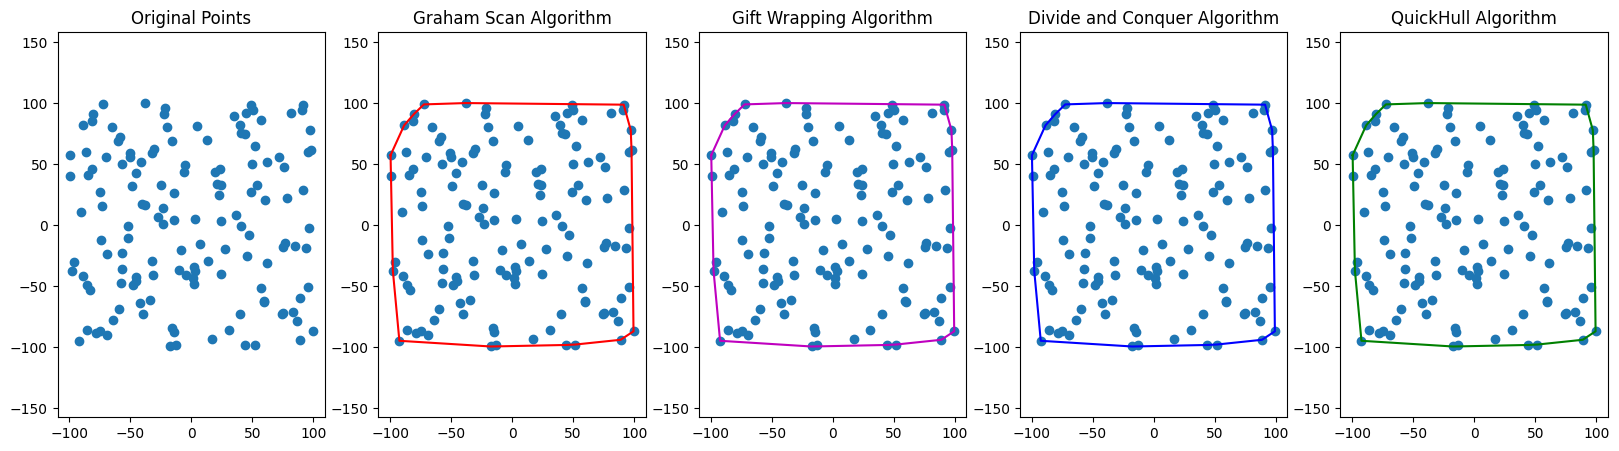

In [7]:
random.seed(394)

# generate 140 random points for testing
points = [(random.uniform(-100, 100), random.uniform(-100, 100)) for _ in range(140)]

# compute convex hulls using the four algorithms
hull_graham_scan = graham_scan(points)
hull_gift_wrapping = gift_wrapping(points)
hull_divide_and_conquer = divide_and_conquer(points)
hull_quickhull = quickhull(points)

# print the points just to see them
print(f"Points: {points}")

plt.figure(figsize=(20, 5))

# Original points
plt.subplot(1, 5, 1)
plt.scatter(*zip(*points), label='Points')
plt.title('Original Points')
plt.axis('equal')

# Graham Scan
plt.subplot(1, 5, 2)
plt.scatter(*zip(*points), label='Points')
# plot hull points connected, closing loop by adding first point at end
plt.plot(*zip(*(hull_graham_scan + [hull_graham_scan[0]])), 'r-', label='Convex Hull')
plt.title('Graham Scan Algorithm')
plt.axis('equal')

# Gift Wrapping
plt.subplot(1, 5, 3)
plt.scatter(*zip(*points), label='Points')
plt.plot(*zip(*(hull_gift_wrapping + [hull_gift_wrapping[0]])), 'm-', label='Convex Hull')
plt.title('Gift Wrapping Algorithm')
plt.axis('equal')

# Divide and Conquer
plt.subplot(1, 5, 4)
plt.scatter(*zip(*points), label='Points')
plt.plot(*zip(*(hull_divide_and_conquer + [hull_divide_and_conquer[0]])), 'b-', label='Convex Hull')
plt.title('Divide and Conquer Algorithm')
plt.axis('equal')

# QuickHull
plt.subplot(1, 5, 5)
plt.scatter(*zip(*points), label='Points')
plt.plot(*zip(*(hull_quickhull + [hull_quickhull[0]])), 'g-', label='Convex Hull')
plt.title('QuickHull Algorithm')
plt.axis('equal')

plt.show()

Και οι τέσσερις αλγόριθμοι δίνουν το ίδιο περίβλημα για το σύνολο των 140 σημείων, όπως φαίνεται στα γραφήματα. Το αποτέλεσμα είναι αναμενόμενο, αφού το κυρτό περίβλημα ενός συνόλου σημείων είναι μοναδικό και οι αλγόριθμοι διαφέρουν μόνο ως προς τον τρόπο και το κόστος υπολογισμού του.

## 3. Σύγκριση των αλγορίθμων ως προς τον χρόνο εκτέλεσης για διαφορετικά πλήθη σημείων

In [15]:
# measure how long an algorithm takes to run on given points
def time_algorithm(algorithm, points):
    start_time = time.time()
    algorithm(points)
    return time.time() - start_time

# different sizes of input to test performance
sizes = [50, 500, 5000, 50000, 1000000]

# dictionary to store timings for each algorithm
timings = {
    "Size": [],
    "Graham Scan": [],
    "Gift Wrapping": [],
    "Divide and Conquer": [],
    "QuickHull": []
}

# for each size, generate random points and time each algorithm
for size in sizes:
    points = [(random.uniform(-100, 100), random.uniform(-100, 100)) for _ in range(size)]

    timings["Size"].append(size)
    timings["Graham Scan"].append(time_algorithm(graham_scan, points))
    timings["Gift Wrapping"].append(time_algorithm(gift_wrapping, points))
    timings["Divide and Conquer"].append(time_algorithm(divide_and_conquer, points))
    timings["QuickHull"].append(time_algorithm(quickhull, points))

# dataframe to display the timings (yay, pandas!)
timing_df = pd.DataFrame(timings)
timing_df

,Size,Graham Scan,Gift Wrapping,Divide and Conquer,QuickHull
0,50,0.000055,0.000081,0.000207,0.000081
1,500,0.000445,0.001560,0.002090,0.000486
2,5000,0.005430,0.023751,0.024640,0.005386
3,50000,0.077335,0.168249,0.349766,0.049874
4,1000000,2.242610,7.433157,14.977306,1.246773


##### Οι χρόνοι εκτέλεσης μετρήθηκαν για 50 έως 1.000.000 τυχαία σημεία μέσα σε τετράγωνο, με μία μέτρηση ανά μέγεθος.

### **Graham Scan**

Δεύτερος σε ταχύτητα (2,24 s). Ο χρόνος κυριαρχείται από την ταξινόμηση και δεν εξαρτάται από το μέγεθος του περιβλήματος.

---

### **Gift Wrapping (Jarvis March)**

Στο 1.000.000 σημεία χρειάστηκε 7,4 s, ενώ στα 50.000 περίπου 0,17 s. Ο χρόνος του είναι O(n·h), και επειδή στα τυχαία σημεία του τετραγώνου το h παραμένει μικρό, ο αλγόριθμος ήταν ταχύτερος από τον Divide & Conquer. Με σημεία πάνω σε κύκλο (h = n) θα έπεφτε σε O(n²).

---

### **Divide and Conquer**

Ήταν ο πιο αργός σε όλα τα μεγέθη, φτάνοντας τα 15 s στο 1.000.000 σημεία. Η αιτία εντοπίζεται στην υλοποίηση: η ταξινόμηση και η αφαίρεση διπλοτύπων επαναλαμβάνονται σε κάθε αναδρομική κλήση, οπότε το πραγματικό κόστος είναι O(n log² n) και όχι O(n log n).

---

### **QuickHull**

Ήταν ο ταχύτερος για μεγάλα n (1,25 s στο 1.000.000 σημεία). Στα τυχαία σημεία οι διαχωρισμοί είναι περίπου ισορροπημένοι και πολλά σημεία απορρίπτονται νωρίς, οπότε το κόστος πλησιάζει το O(n log n). Η χειρότερη περίπτωση O(n²) δεν εμφανίστηκε σε αυτά τα δεδομένα.

---

### **Συμπέρασμα**

Για τυχαία σύνολα σημείων ο QuickHull είναι η καλύτερη επιλογή και ο Graham Scan μια σταθερή εναλλακτική που δεν εξαρτάται από το h. Τα συμπεράσματα ισχύουν για αυτή την κατανομή σημείων, και με διαφορετική κατανομή (π.χ. σημεία στον κύκλο) η σειρά θα άλλαζε.

## 4. Υλοποίηση του αλγορίθμου QuickHull για την εύρεση κυρτού περιβλήματος σε 3 διαστάσεις

In [ ]:
def gift_wrapping_3d(points, tol=None, debug=False):

    P = np.asarray(points, dtype=float)
    n = len(P)
    if n < 4:
        raise ValueError("Need at least 4 non-coplanar points for a 3D convex hull.")

     # if no tolerance, calculate one based on the size of the point set
    if tol is None:
        L = np.linalg.norm(P.max(axis=0) - P.min(axis=0))  # bbox diagonal length
        tol = 1e-9 * (L**2 + 1.0)

    C = P.mean(axis=0)  # centroid of all points

    # make sure the triangle has outward orientation
    def fix_orientation(u, v, w):
        a, b, c = P[u], P[v], P[w]
        n = np.cross(b - a, c - a)
        if np.linalg.norm(n) == 0:
            return None  # points are colinear
        # if pointing toward centroid, flip it
        if np.dot(n, C - a) > 0:
            return (u, w, v)
        return (u, v, w)

    # for a point, find the farthest point in the direction of the normal
    def max_signed_distance(u, v, w):
        a, b, c = P[u], P[v], P[w]
        n = np.cross(b - a, c - a)  # normal
        nn = np.linalg.norm(n)
        if nn == 0:
            return float('inf') # degenerate triangle
        # if pointing toward centroid, flip it
        if np.dot(n, C - a) > 0:
            n = -n
        s = (P - a) @ n # distances from all points to the plane
        return s.max()

    # 1 - choose a starting point with the smallest x (then y, then z)
    start = int(np.lexsort((P[:, 2], P[:, 1], P[:, 0]))[0])

    # 2 - find the first face of the convex hull
    # test all pairs and third points, keep the one with smallest max distance
    best_j = best_k = None
    best_val = float('inf')
    for j in range(n):
        if j == start:
            continue
        for k in range(n):
            if k == start or k == j:
                continue
            val = max_signed_distance(start, j, k)
            if val < best_val:
                best_val, best_j, best_k = val, j, k
    if debug:
        print(f"[init] best supporting error: {best_val:.3e}")

    tri = fix_orientation(start, best_j, best_k)
    if tri is None:
        raise RuntimeError("Failed to initialize a non-degenerate starting face.")

    # 3 - explore edges to find all hull faces
    faces_set = {tuple(sorted(tri))}      # keep track of faces weve already added
    oriented_faces = [tri]                # keep oriented faces, for plotting
    edge_to_ws = {                        # map an edge to the set of third vertices that form a face with it
        frozenset((tri[0], tri[1])): {tri[2]},
        frozenset((tri[1], tri[2])): {tri[0]},
        frozenset((tri[2], tri[0])): {tri[1]},
    }

    from collections import deque
    dq = deque([(tri[0], tri[1]), (tri[1], tri[2]), (tri[2], tri[0])])

    while dq:
        u, v = dq.popleft()
        ekey = frozenset((u, v))
        known_ws = edge_to_ws.get(ekey, set())
        if len(known_ws) >= 2:
            # already have both adjacent hull faces
            continue

        # choose the one minimizing the max signed distance
        best_w = None
        best_val = float('inf')
        for w in range(n):
            if w == u or w == v or w in known_ws:
                continue
            val = max_signed_distance(u, v, w)
            if val < best_val:
                best_val, best_w = val, w

        if best_w is None:
            continue

        # supporting within tolerance
        if best_val <= tol:
            tri = fix_orientation(u, v, best_w)
            if tri is None:
                continue
            key = tuple(sorted(tri))
            if key not in faces_set:
                faces_set.add(key)
                oriented_faces.append(tri)
                # register edges and schedule exploration
                for a, b, c in [(tri[0], tri[1], tri[2]),
                                (tri[1], tri[2], tri[0]),
                                (tri[2], tri[0], tri[1])]:
                    fe = frozenset((a, b))
                    s = edge_to_ws.get(fe)
                    if s is None:
                        s = set()
                        edge_to_ws[fe] = s
                    if c not in s:
                        s.add(c)
                        dq.append((a, b))
        else:
            # oriented edge does not lead to a hull face.
            pass

    return oriented_faces  # each face is an oriented triple of indices

Ο κώδικας υλοποιεί τον Gift Wrapping (Jarvis March) σε τρεις διαστάσεις. Υπολογίζεται πρώτα το κέντρο των σημείων, που βρίσκεται σίγουρα μέσα στο περίβλημα και χρησιμοποιείται για να προσανατολίζονται οι κανονικές των προσώπων προς τα έξω. Ως αφετηρία επιλέγεται το σημείο με τη μικρότερη συντεταγμένη x (και σε ισοβαθμία, y και z), και δοκιμάζονται όλα τα ζεύγη των υπόλοιπων σημείων ώστε να βρεθεί το τρίγωνο με το οποίο όλα τα σημεία βρίσκονται από την ίδια πλευρά του επιπέδου του, δηλαδή ένα πρώτο πρόσωπο του περιβλήματος.

Στη συνέχεια το περίβλημα «τυλίγεται» ακμή προς ακμή. Για κάθε ακμή ενός ήδη γνωστού προσώπου επιλέγεται το σημείο που σχηματίζει μαζί της το τρίγωνο με όλα τα σημεία στην ίδια πλευρά, δηλαδή το διπλανό πρόσωπο, και οι νέες ακμές μπαίνουν σε ουρά. Η διαδικασία τελειώνει όταν κάθε ακμή έχει δύο γειτονικά πρόσωπα. Επιστρέφεται η λίστα των τριγωνικών προσώπων με προσανατολισμό προς τα έξω.

### Ανάλυση πολυπλοκότητας

Έστω n ο αριθμός των σημείων και f ο αριθμός των προσώπων. Για κάθε ακμή δοκιμάζονται και τα n σημεία, και κάθε δοκιμή υπολογίζει την απόσταση από όλα τα σημεία, οπότε η εξερεύνηση κοστίζει O(n²·f). Η εύρεση του αρχικού προσώπου κοστίζει O(n³), αφού εξετάζονται O(n²) ζεύγη και κάθε ζεύγος κοστίζει O(n). Επειδή f ≤ 2n − 4, η χρονική πολυπλοκότητα στη χειρότερη περίπτωση είναι O(n³). Η υλοποίηση προτιμήθηκε για την απλότητά της και όχι για την ταχύτητά της: εξακριβώθηκε ότι δίνει το ίδιο περίβλημα με το SciPy, αλλά δεν είναι κατάλληλη για μεγάλα n. Η χωρική πολυπλοκότητα είναι O(n + f).

## 5. Εφαρμογή του αλγορίθμου περιτυλίγματος για την κατασκευή κυρτού περιβλήματος 120 σημείων στον τρισδιάστατο χώρο

Hull faces: 78
Matches SciPy: True (ours=78, scipy=78)


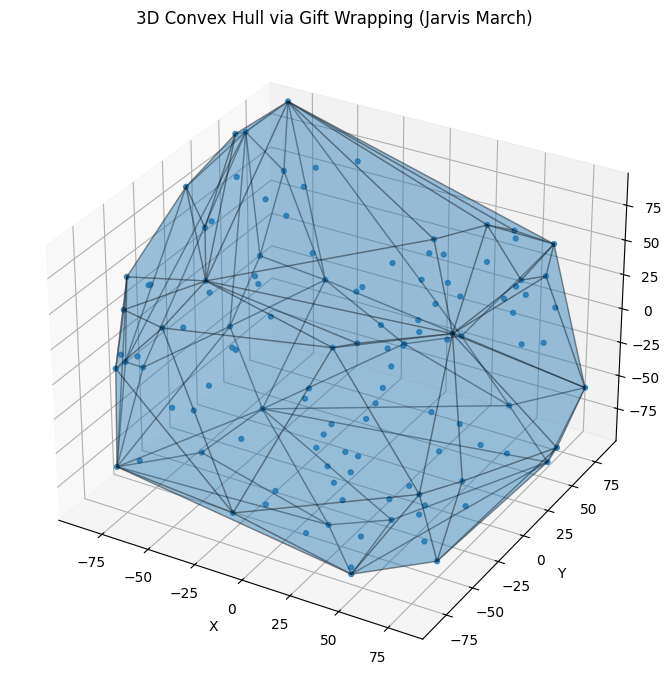

In [ ]:
if __name__ == "__main__":
    np.random.seed(394)
    points = np.random.rand(120, 3) * 200 - 100  # 120 points in [-100,100]^3

    hull_faces = gift_wrapping_3d(points, debug=False)
    print(f"Hull faces: {len(hull_faces)}")

    # --- Optional sanity check if SciPy is available ---
    try:
        from scipy.spatial import ConvexHull
        ch = ConvexHull(points)
        scipy_faces = {tuple(sorted(t)) for t in ch.simplices.tolist()}
        our_faces = {tuple(sorted(f)) for f in hull_faces}
        print("Matches SciPy:", len(our_faces ^ scipy_faces) == 0,
              f"(ours={len(our_faces)}, scipy={len(scipy_faces)})")
    except Exception:
        pass

    # ==============================
    # 3D Plot
    # ==============================
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")

    # plot points
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=12, alpha=0.8)

    # plot hull faces
    polys = [points[list(f)] for f in hull_faces]
    coll = Poly3DCollection(polys, alpha=0.25, edgecolor="k")
    ax.add_collection3d(coll)

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_title("3D Convex Hull via Gift Wrapping (Jarvis March)")
    # auto-fit axes to data extent
    xyz_min = points.min(axis=0)
    xyz_max = points.max(axis=0)
    ax.set_xlim([xyz_min[0], xyz_max[0]])
    ax.set_ylim([xyz_min[1], xyz_max[1]])
    ax.set_zlim([xyz_min[2], xyz_max[2]])
    plt.tight_layout()
    plt.show()

### Τι βλέπουμε στο διάγραμμα:

Το διάγραμμα δείχνει 120 τυχαία σημεία στον κύβο [−100, 100]³ και το κυρτό τους περίβλημα, όπως υπολογίστηκε με τον 3D Gift Wrapping. Το περίβλημα αποτελείται από 78 τριγωνικά πρόσωπα, που σχεδιάζονται ημιδιαφανή με μαύρο περίγραμμα, ώστε να φαίνονται και τα σημεία που βρίσκονται στο εσωτερικό του. Το σύνολο των προσώπων που βρέθηκε ταυτίζεται με αυτό που επιστρέφει η scipy.spatial.ConvexHull για τα ίδια σημεία, γεγονός που επιβεβαιώνει την ορθότητα της υλοποίησης.